# Homework 2: circle detection
*(Visual Recognition 2025/26)*

You are given [fundus photographs](https://en.wikipedia.org/wiki/Fundus_photography) (images of the rear of the human eye).
Your task is to find the circular outline of the image, quickly and robustly.
This is nontrivial, because of all kinds of artifacts (noise, over- and underexposure, obscured or cut-out parts of the image, etc.)
Run the notebook to see examples near the end.

Implement two algorithms:
* A. The first should follow a prescribed approach described below (a variant of the Hough transform). Here you may *not* use existing circle detection implementations like `cv2.HoughCircles`.
* B. The second can be any method of your choice. This can be a significant modification of 1. (more than just changing parameters), or a completely different method: some simple sweeping heuristic, a machine learning model, something based on existing implementations like `cv2.HoughCircles`, etc. You may use a GPU (but this homework can be done without GPUs).

Both algorithms will be graded in the same way, for 75% and 25% of the grade respectively.
Both will be graded on a hidden test set based on the following:
* success rate (how many images are correctly detected, where we define *correct* as IoU > 0.85),
* accuracy: mean of `clip(IoU, min=0.85, max=0.98)` (all incorrect detections are treated equally, IoU above 0.98 is irrelevant),
* speed: the running time of the algorithm on a Colab CPU *must* be below 2s per image on average (you can assume that a warm-up run was performed before measuring times). Be as fast as possible, but prioritize accuracy.

### Algorithm A requirements
For algorithm A, the approach should be as follows:
* Make an array of scores for a range of center coordinates and radii (cy, cx, r).
* For each candidate circle (cy, cx, r), the score should be the sum of contributions from a few points on the circle.
* The contribution of each image point to a candidate circle should be based on the image gradient at that point: consider the gradient vector $(\frac{\partial \texttt{img}}{\partial y}, \frac{\partial \texttt{img}}{\partial x})$. These can be computed with a Sobel or Scharr filter ([`cv2.Scharr()`](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html)).
* The contribution of each image point should be higher when the gradient vector points towards the candidate center and when the gradient is larger.
* Return the (cy, cx, r) with the highest score.
* For best results, consider: how to strengthen the impact of different factors (gradient angle vs gradient norm); how to handle noise in the image and gradient; how to avoid large gradients in bright parts of the image dwarfing the darker borders.
* For speed, consider: in what order to perform operations; how to minimize processed data given that we don't need to be pixel-perfect.
* Make the algorithm iterative (with 2 or 3 steps): first run it to obtain a rough estimate, then run it again on a finer choice of candidate circle parameters.
* Use *numba* to make the algorithm fast on CPU.
  
Please make sure to ***only modify sections `Algorithm A` and `Algorithm B`*** of the notebook.
You may add imports (available on Colab), functions, shared code, etc. there, but make sure the notebook can be executed unattended from top to bottom without errors in a reasonable time,
resulting in functions `find_circle_A` and `find_circle_B` being defined (for automated tests).
If you add any heavy computations like evaluations, put them in extra sections at the end.

### Numba
Numba is a just-in-time compiler that is easy to use with numpy code. See [docs](https://numba.readthedocs.io/en/stable/user/5minguide.html). In short, this is all you need to know:
* Use the `@numba.njit` decorator on a function: it will be automatically compiled on first usage: this takes a while, but the resulting function is usually much faster.
* Not all code can be used in functions JITed with numba:
    * Limit usage to int/float and numpy.ndarray types (especially function arguments).
    * Most numpy functions are available, but a few will throw errors: you may need to replace them with more elementary implementations.
* For this reason, you will probably need to limit numba to a helper function that only does the heavy computation.
* You often do not need to vectorize your code at all, since numba's JIT compiler optimizes simple nested `for` loops very well.
    
### OpenCV
OpenCV is a popular computer vision library with many functions from basic image processing, edge detection, to 3D waypoint estimation and more.
The Python package (`cv2`) is essentially just bindings to the C++ library, so it is very fast, but also a quite clunky to use at times.
Their documentation focuses on the C++ API: e.g. output arrays are often function arguments in C++, but returned values in Python.
When in doubt, check the examples/tutorials in the documentation.

## Imports

In [ ]:
import json
import math
import time
from collections.abc import Callable, Iterable, Sequence
from functools import partial
from pathlib import Path
from typing import TypedDict, cast

import cv2
import ipywidgets
import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
import PIL.Image
import PIL.ImageDraw
from IPython.display import display
from tqdm.contrib.concurrent import process_map

## Dataset
The dataset is based on a [Kaggle dataset](https://www.kaggle.com/competitions/diabetic-retinopathy-detection/overview) of fundus photographs for diagnosing diabetic retinopathy.
However, it is much smaller, downscaled, and modified to exaggerate the artifacts according to a difficulty parameter 0..90.

* It is split into three parts: 1000 train images, 100 validation images, and a lot of test images (hidden).
* You are given ground-truths for the small validation set only.
* In each part, you have subfolders of equal size for each difficulty level (0, 10, 20, ..., 90).
    They are only here to help you estimate the performance of your algorithms.
    Difficulty 0 are unmodified images – already quite challenging, but all solvable.
    As difficulty increases, a few images may be even impossible to decide – don't expect 100% success rate.
* The test set follows the same distribution.
* You may assume that all images satisfy the following (where $H,W$ are image dimensions, $r$ is the radius in pixels, $\langle cy, cx \rangle$ is the center in pixel coordinates):
    * the center is comfortably within image bounds: $0.3\,H \leq cy \leq 0.7\,H$ and $0.3\,W \leq cx \leq 0.7\,W$
    * each corner of the image is at least $1.2r$ away from the center.
    * $0.25\,\max(H, W) \leq r \leq 0.75\,\min(H, W)$
    


In [ ]:
# added imports
from pathlib import Path
from typing import TypedDict, Callable
import json
import pandas as pd
import PIL
from PIL import Image
from collections.abc import Iterable, Sequence
import numpy as np
import cv2
import matplotlib.pyplot as plt
import itertools
from functools import partial
import csv
from tqdm import tqdm
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch.nn as nn
import torchvision.models as models

In [ ]:
%%bash
mkdir -p data/
if [ ! -d "data/circle/train" ]; then
    # 50 MiB disk space
    wget -q 'https://www.mimuw.edu.pl/~mw290715/upload/circle.tar.gz' -O data/circle.tar.gz
    cd data/
    tar -xf circle.tar.gz
    cd -
fi

/content


In [ ]:
IMG_DIR = Path("data/circle/")
train_set = sorted((IMG_DIR / "train").rglob("*.webp"))
val_set = sorted((IMG_DIR / "val").rglob("*.webp"))
assert len(train_set) == 1000 and len(val_set) == 100, (
    "Bad number of images in train/val sets."
)

In [ ]:
class Result(TypedDict):
    path: str  # Relative to IMG_DIR. Always an RGB webp image.
    h: int  # Image height.
    w: int  # Image width.
    cy: int  # Y coordinate of circle center.
    cx: int  # X coordinate of circle center.
    r: int  # Radius of the circle.
    duration: float  # Time taken to find the circle, in seconds.

In [ ]:
GROUND_TRUTHS: dict[Path, Result] = {}

for part in ("train", "val", "test"):
    if not (IMG_DIR / f"{part}.json").exists():
        continue
    with (IMG_DIR / f"{part}.json").open() as f:
        for result in json.load(f):
            GROUND_TRUTHS[IMG_DIR / result["path"]] = result

df = pd.DataFrame.from_dict(GROUND_TRUTHS, orient="index")
df["difficulty"] = df.index.map(lambda p: p.parent.name)
df.head()

,path,h,w,cy,cx,r,difficulty
data/circle/val/00/00000.webp,val/00/00000.webp,1000,1504,508,736,470,00
data/circle/val/00/00001.webp,val/00/00001.webp,960,1280,479,639,563,00
data/circle/val/00/00002.webp,val/00/00002.webp,779,1168,383,586,478,00
data/circle/val/00/00003.webp,val/00/00003.webp,864,1296,445,651,540,00
data/circle/val/00/00004.webp,val/00/00004.webp,779,1168,395,585,518,00


## Evaluation utils

In [ ]:
def run_algorithm(
    img_path: Path,
    algo: Callable[[PIL.Image.Image], tuple[int, int, int]],
) -> Result:
    pil_img = PIL.Image.open(img_path)
    start_time = time.perf_counter()
    cy, cx, r = algo(pil_img)
    duration = time.perf_counter() - start_time
    return {
        "path": str(img_path.relative_to(IMG_DIR)),
        "h": pil_img.height,
        "w": pil_img.width,
        "cy": cy,
        "cx": cx,
        "r": r,
        "duration": round(duration, 4),
    }

In [ ]:
class ResultWithComparison(Result):
    c_dist: float  # Distance from predicted to GT center, as ratio of image width.
    r_diff: float  # Difference of predicted minus GT radius (possibly negative), as ratio of GT radius.
    iou: float  # Intersection over Union of predicted vs GT disc. Between 0 and 1.


def get_iou(pred: tuple[int, int, int], gt: tuple[int, int, int]) -> float:
    """IoU of two circles, each specified as (cy, cx, r)."""
    pred_cy, pred_cx, pred_r = pred
    gt_cy, gt_cx, gt_r = gt

    d = math.hypot(pred_cy - gt_cy, pred_cx - gt_cx)
    r1, r2 = max(pred_r, gt_r), min(pred_r, gt_r)

    if d >= pred_r + gt_r:
        return 0.0
    elif d <= r1 - r2:
        return math.pi * (r2**2) / (math.pi * (r1**2))

    # https://mathworld.wolfram.com/Circle-CircleIntersection.html
    d1 = (r1**2 - r2**2 + d**2) / (2 * d)
    d2 = d - d1
    t = 0.5 * math.sqrt((-d + r1 + r2) * (d + r1 - r2) * (d - r1 + r2) * (d + r1 + r2))
    intersection_area = r2**2 * math.acos(d2 / r2) + r1**2 * math.acos(d1 / r1) - t
    union_area = math.pi * (pred_r**2 + gt_r**2) - intersection_area
    return intersection_area / union_area


def run_and_compare(
    img_path: Path, algo: Callable[[PIL.Image.Image], tuple[int, int, int]]
) -> ResultWithComparison:
    pred = run_algorithm(img_path, algo=algo)
    if img_path not in GROUND_TRUTHS:
        return {
            **pred,
            "c_dist": float("nan"),
            "r_diff": float("nan"),
            "iou": float("nan"),
        }
    gt = GROUND_TRUTHS[img_path]
    c_dist = np.hypot(pred["cy"] - gt["cy"], pred["cx"] - gt["cx"]) / gt["w"]
    r_diff = (pred["r"] - gt["r"]) / gt["r"]
    iou = get_iou((pred["cy"], pred["cx"], pred["r"]), (gt["cy"], gt["cx"], gt["r"]))
    return {
        **pred,
        "c_dist": round(float(c_dist), 4),
        "r_diff": round(float(r_diff), 4),
        "iou": round(float(iou), 4),
    }


def run_all(
    img_paths: Iterable[Path],
    algo: Callable[[PIL.Image.Image], tuple[int, int, int]],
    num_workers: int = 2,
) -> list[ResultWithComparison]:
    return process_map(
        partial(run_and_compare, algo=algo), img_paths, max_workers=num_workers
    )

## Visualization

In [ ]:
def show_result(
    result: Result, gt: Result | None = None, max_height: int = 512
) -> PIL.Image.Image:
    print(result)
    pil_img = PIL.Image.open(IMG_DIR / result["path"])
    draw = PIL.ImageDraw.Draw(pil_img)

    # Draw ground truth in red, behind, with a small circle at the center.
    if gt:
        xy = (gt["cx"], gt["cy"])
        draw.circle(xy=xy, radius=gt["r"], outline="red", width=2)
        draw.circle(xy=xy, radius=30, outline="red", width=2)

    # Draw this result in blue, with a small circle at the center.
    xy = (result["cx"], result["cy"])
    draw.circle(xy=xy, radius=result["r"], outline="blue", width=3)
    draw.circle(xy=xy, radius=30, outline="blue", width=3)

    downscale = max(1, math.ceil(pil_img.height / max_height))
    return pil_img.reduce(downscale)


def show_results(
    img_paths: Sequence[Path] | pd.Index,
    algo: Callable[[PIL.Image.Image], tuple[int, int, int]],
    init_i: int = 0,
) -> None:
    if isinstance(img_paths, pd.Index):
        img_paths = cast(Sequence[Path], img_paths)

    def f(i: int) -> None:
        print(f"Image {i + 1}/{len(img_paths)}: {img_paths[i].name}")
        if img_paths[i] in GROUND_TRUTHS:
            result = run_and_compare(img_paths[i], algo=algo)
            display(show_result(result, GROUND_TRUTHS[img_paths[i]]))
        else:
            result = run_algorithm(img_paths[i], algo=algo)
            display(show_result(result))

    ipywidgets.interact(
        f, i=ipywidgets.IntSlider(min=0, max=len(img_paths) - 1, value=init_i)
    )

In [ ]:
def find_circle_baseline(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    cy, cx, r = (
        pil_img.height // 2,
        pil_img.width // 2,
        min(pil_img.height, pil_img.width) // 2,
    )
    return cy, cx, r

In [ ]:
results = run_all(val_set, algo=find_circle_baseline)
results_df = pd.DataFrame(results)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

  0%|          | 0/100 [00:00<?, ?it/s]

,path,h,w,cy,cx,r,duration,c_dist,r_diff,iou,difficulty
index,,,,,,,,,,,
data/circle/val/00/00000.webp,val/00/00000.webp,1000,1504,500,752,500,0.0,0.0119,0.0638,0.8836,00
data/circle/val/00/00001.webp,val/00/00001.webp,960,1280,480,640,480,0.0,0.0011,-0.1474,0.7269,00
data/circle/val/00/00002.webp,val/00/00002.webp,779,1168,389,584,389,0.0,0.0054,-0.1862,0.6623,00
data/circle/val/00/00003.webp,val/00/00003.webp,864,1296,432,648,432,0.0,0.0103,-0.2000,0.6400,00
data/circle/val/00/00004.webp,val/00/00004.webp,779,1168,389,584,389,0.0,0.0052,-0.2490,0.5639,00
...,...,...,...,...,...,...,...,...,...,...,...
data/circle/val/90/00005.webp,val/90/00005.webp,704,1572,352,786,352,0.0,0.0109,-0.2621,0.5446,90
data/circle/val/90/00006.webp,val/90/00006.webp,820,1320,410,660,410,0.0,0.0552,-0.2718,0.5303,90
data/circle/val/90/00007.webp,val/90/00007.webp,981,2018,490,1009,490,0.0,0.1037,-0.0649,0.5821,90


In [ ]:
success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

Success Rate: 11.0%, Accuracy: 85.52%


The visualization shows:
* the ground truth in red;
* the prediction of a given algorithm in blue.
* for both: a smaller circle around the center.

In [ ]:
# ordering = train_set
ordering = df.index
# ordering = (df["r"] / df["w"]).sort_values(ascending=True).index
# ordering = results_df.sort_values("iou", ascending=True).index
show_results(ordering, algo=find_circle_baseline)

interactive(children=(IntSlider(value=0, description='i', max=99), Output()), _dom_classes=('widget-interact',…

## Algorithm A

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=2, tileGridSize=(8,8))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

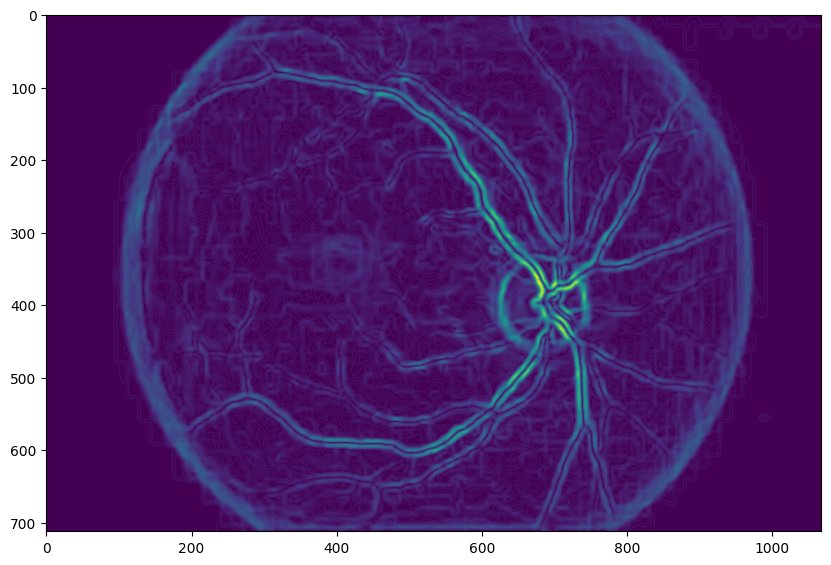

In [ ]:
image = PIL.Image.open(val_set[5])
x_grad, y_grad, grad_norm = obtain_gradients(image)

plt.figure(figsize=(10,10))
plt.imshow(grad_norm)
plt.show()

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        input_candidate = scalar_product / np.sqrt(grad_norm_candidate + 1e-6)
        input_candidate = min(input_candidate, 50.0)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
def obtain_candidates(x_min, x_max, dx, y_min, y_max, dy, r_min, r_max, dr, h, w):
  """Function that return the array with candidate circles."""

  # parameters to test
  xs = np.arange(start=x_min, stop=x_max, step=dx)
  ys = np.arange(start=y_min, stop=y_max, step=dy)
  rs = np.arange(start=r_min, stop=r_max, step=dr)

  # creating meshgrid
  X, Y, R = np.meshgrid(xs, ys, rs, indexing='ij')

  # flattening the above matrices
  X = X.ravel()
  Y = Y.ravel()
  R = R.ravel()

  # Using information: distance from corners >= 1.2r

  # computing distances from corners
  d_up_right = np.sqrt((w - X) ** 2 + Y ** 2)
  d_up_left = np.sqrt(X ** 2 + Y ** 2)
  d_down_right = np.sqrt((w - X) ** 2 + (h - Y) ** 2)
  d_down_left = np.sqrt(X ** 2 + (h - Y) ** 2)

  # minimal distance from corners
  min_dist = np.minimum(np.minimum(np.minimum(d_up_right, d_up_left), d_down_right), d_down_left)

  mask = (min_dist >= 1.2 * R)

  # filtering using mask
  X = X[mask]
  Y = Y[mask]
  R = R[mask]

  # joining the matrices into one matrix
  matrix_combined = np.column_stack((Y, X, R))

  # adjusting type
  matrix_combined = matrix_combined.astype(np.float32)

  return matrix_combined

In [ ]:
def find_circle_A(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    big_step = 15
    candidates_phase_1 = obtain_candidates(x_min=0, x_max=w, dx=big_step, y_min=0, y_max=h, dy=big_step, r_min=300, r_max=max(h, w) // 2+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
img_path = val_set[70]
image = PIL.Image.open(img_path)
print(image.height, image.width)

result = run_and_compare(img_path, algo=find_circle_A)
gt = GROUND_TRUTHS[img_path]
show_result(result, gt=gt)

In [ ]:
results_A = run_all(val_set, algo=find_circle_A)
results_A

In [ ]:
results_df = pd.DataFrame(results_A)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

In [ ]:
# new
success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# old
success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def find_circle_A_2(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 15
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_2 = run_all(val_set, algo=find_circle_A_2)

results_df = pd.DataFrame(results_A_2)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# old
results_A_2 = run_all(val_set, algo=find_circle_A_2)

results_df = pd.DataFrame(results_A_2)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def find_circle_A_3(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 7
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_3 = run_all(val_set, algo=find_circle_A_3)

results_df = pd.DataFrame(results_A_3)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# old
results_A_3 = run_all(val_set, algo=find_circle_A_3)

results_df = pd.DataFrame(results_A_3)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def find_circle_A_4(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=10.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_4 = run_all(val_set, algo=find_circle_A_4)

results_df = pd.DataFrame(results_A_4)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# old
results_A_4 = run_all(val_set, algo=find_circle_A_4)

results_df = pd.DataFrame(results_A_4)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def find_circle_A_5(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 5
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_5 = run_all(val_set, algo=find_circle_A_5)

results_df = pd.DataFrame(results_A_5)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def find_circle_A_6(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 7
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_6 = run_all(val_set, algo=find_circle_A_6)

results_df = pd.DataFrame(results_A_6)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# testing lower `big_step` value in regard to 6th pipeline
def find_circle_A_7(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_7 = run_all(val_set, algo=find_circle_A_7)

results_df = pd.DataFrame(results_A_7)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# testing higher `blur_kernel_size` in regard to 6th pipeline
def find_circle_A_8(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img, blur_kernel_size=21)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 7
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_8 = run_all(val_set, algo=find_circle_A_8)

results_df = pd.DataFrame(results_A_8)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# testing lower `blur_kernel_size` in regard to 6th pipeline
def find_circle_A_9(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img, blur_kernel_size=7)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 7
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_9 = run_all(val_set, algo=find_circle_A_9)

results_df = pd.DataFrame(results_A_9)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# testing much higher `blur_kernel_size` in regard to 6th pipeline
def find_circle_A_10(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img, blur_kernel_size=31)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 7
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_10 = run_all(val_set, algo=find_circle_A_10)

results_df = pd.DataFrame(results_A_10)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

`blur_kernel_size`=21 seems optimal

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(8,8))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.medianBlur(image_binary, blur_kernel_size)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing median blur instead of gaussian blur
def find_circle_A_11(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = big_step
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_11 = run_all(val_set, algo=find_circle_A_11)

results_df = pd.DataFrame(results_A_11)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

testing next upgrades


In [ ]:
# testing higher `search_radius`
def find_circle_A_12(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=1.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=1.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_12 = run_all(val_set, algo=find_circle_A_12)

results_df = pd.DataFrame(results_A_12)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        input_candidate = scalar_product / np.sqrt(grad_norm_candidate + 1e-6)
        input_candidate = min(input_candidate, 100.0)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_13(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_13 = run_all(val_set, algo=find_circle_A_13)

results_df = pd.DataFrame(results_A_13)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate

        candidate_sum += cos_angle

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_14(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_14 = run_all(val_set, algo=find_circle_A_14)

results_df = pd.DataFrame(results_A_14)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 3) * np.sqrt(grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_15(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# THIS HAS GREAT POTENTIAL
results_A_15 = run_all(val_set, algo=find_circle_A_15)

results_df = pd.DataFrame(results_A_15)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        x = grad_norm_candidate / 20.0
        weight = 1.0 / (1.0 + np.exp(-x))
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = cos_angle * weight

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_16(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_16 = run_all(val_set, algo=find_circle_A_16)

results_df = pd.DataFrame(results_A_16)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (blur_kernel_size, blur_kernel_size))
  image_gray = cv2.morphologyEx(image_gray, cv2.MORPH_OPEN, kernel)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.medianBlur(image_binary, blur_kernel_size)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        input_candidate = scalar_product / np.sqrt(grad_norm_candidate + 1e-6)
        input_candidate = min(input_candidate, 50.0)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_17(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_17 = run_all(val_set, algo=find_circle_A_17)

results_df = pd.DataFrame(results_A_17)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=2, tileGridSize=(8,8))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_18(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_18 = run_all(val_set, algo=find_circle_A_18)

results_df = pd.DataFrame(results_A_18)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# ordering = train_set
ordering = df.index
# ordering = (df["r"] / df["w"]).sort_values(ascending=True).index
# ordering = results_df.sort_values("iou", ascending=True).index
show_results(ordering, algo=find_circle_A_18)

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (blur_kernel_size, blur_kernel_size))
  image_gray = cv2.morphologyEx(image_gray, cv2.MORPH_OPEN, kernel)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.medianBlur(image_binary, blur_kernel_size)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_19(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_19 = run_all(val_set, algo=find_circle_A_19)

results_df = pd.DataFrame(results_A_19)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(8,8))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_20(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_20 = run_all(val_set, algo=find_circle_A_20)

results_df = pd.DataFrame(results_A_20)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4,4))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_21(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_21 = run_all(val_set, algo=find_circle_A_21)

results_df = pd.DataFrame(results_A_21)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(6,6))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_22(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_22 = run_all(val_set, algo=find_circle_A_22)

results_df = pd.DataFrame(results_A_22)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(6,6))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 7) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_23(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_23 = run_all(val_set, algo=find_circle_A_23)

results_df = pd.DataFrame(results_A_23)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        cos_score = cos_angle ** 5
        classic_score = min(scalar_product / np.sqrt(grad_norm_candidate + 1e-6), 50.0)
        input_candidate = cos_score + classic_score

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_24(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_24 = run_all(val_set, algo=find_circle_A_24)

results_df = pd.DataFrame(results_A_24)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

uprading 21th

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4,4))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_25(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=256, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_25 = run_all(val_set, algo=find_circle_A_25)

results_df = pd.DataFrame(results_A_25)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
# testing new `scoring_function`
def find_circle_A_26(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=512, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_26 = run_all(val_set, algo=find_circle_A_26)

results_df = pd.DataFrame(results_A_26)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

TODO:


1.   napisac dobry early stopping aby zejsc ponizej 2 sek na wiekszej ilosci punktow
2.   poczyscic te sekcje z Alorithm A
3. przejsc do B i je zrobic



In [ ]:
# this is an attempt to make the pipeline faster, while being more precise -> introducing fast_check
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0, n_fast_points=32, threshold_2=2.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points
  d_angle_fast = 2 * np.pi / n_fast_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    fast_candidate_sum = 0.0

    for k in range(n_fast_points):
      # updating angle
      angle = d_angle_fast * k

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        fast_candidate_sum += input_candidate

    # skipping this candidate if it didn't perform during fast check
    if fast_candidate_sum < threshold_2:
      results[i] = 0
      continue

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum + fast_candidate_sum

  return results

In [ ]:
# testing new `scoring_function`
def find_circle_A_27(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step, dr=big_step, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=512, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_27 = run_all(val_set, algo=find_circle_A_27)

results_df = pd.DataFrame(results_A_27)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

In [ ]:
@numba.njit
def scoring_function(candidates, x_grad, y_grad, grad_norm, n_points, threshold=1.0):
  """Function designed to calculate scores for candidate circles based on the strength of the gradient."""
  h, w = x_grad.shape
  n_candidates = len(candidates)

  # creating placeholder for results
  results = np.zeros(n_candidates)

  # angle step
  d_angle = 2 * np.pi / n_points

  for i in range(candidates.shape[0]):
    # obtaining details about candidate
    cy = candidates[i, 0]
    cx = candidates[i, 1]
    r = candidates[i, 2]

    candidate_sum = 0.0

    for j in range(n_points):
      # updating angle
      angle = d_angle * j

      # calculating position of point
      x = cx + r * np.cos(angle)
      y = cy + r * np.sin(angle)

      # rounding to get the nearest pixel
      x = int(np.round(x))
      y = int(np.round(y))

      # checking whether we didn't fall outside the image
      if x < 0 or x >= w or y < 0 or y >= h:
        continue

      # getting gradients from passed `x_grad` and `y_grad`
      x_grad_candidate = x_grad[y, x]
      y_grad_candidate = y_grad[y, x]
      grad_norm_candidate = grad_norm[y, x]

      # to filter out the noise we only consider cases when gradient is strong enough
      if grad_norm_candidate < threshold:
        continue

      # vector that should be pointing at the center
      x_vector = -np.cos(angle)
      y_vector = -np.sin(angle)

      # computing scalar product
      scalar_product = x_vector * x_grad_candidate + y_vector * y_grad_candidate

      # checking if gradient vector is pointed in correct direction
      if scalar_product > 0:
        # mitigating the impact of huge gradients by dividing by the square root of gradient norm
        # calculating the input of this point for this candidate
        cos_angle = scalar_product / grad_norm_candidate
        input_candidate = (cos_angle ** 5) * (grad_norm_candidate)

        candidate_sum += input_candidate

    # updating results
    results[i] = candidate_sum

  return results

In [ ]:
def obtain_gradients(image, blur_kernel_size=15):
  """Helper function that prepares gradients for `find_circle_A` for further work."""

  image_np = np.array(image)

  # converting to grayscale
  image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

  # NEW UPDATE
  clahe = cv2.createCLAHE(clipLimit=2, tileGridSize=(8,8))
  image_gray = clahe.apply(image_gray)

  # converting to binary image: non-black pixel becomes white
  image_binary = image_gray
  #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

  # applying smoothing to reduce the impact of noise/structure of the eye itself
  image_smoothed = cv2.GaussianBlur(image_binary, ksize=(blur_kernel_size, blur_kernel_size), sigmaX=0)

  # computing gradients using `cv2.Scharr`
  x_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=1, dy=0)
  y_grad = cv2.Scharr(image_smoothed, ddepth=cv2.CV_32F, dx=0, dy=1)

  # TODO information that in some way will be used to mitigate the influence of gradient
  grad_norm = np.sqrt(x_grad ** 2 + y_grad ** 2)

  return (x_grad, y_grad, grad_norm)

In [ ]:
# testing new `scoring_function`
def find_circle_A_28(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)

    h = pil_img.height
    w = pil_img.width

    # calculating gradients
    x_grad, y_grad, grad_norm = obtain_gradients(image=pil_img, blur_kernel_size=21)

    # Phase 1
    y_min = int(0.3*h)
    y_max = int(0.7*h)
    x_min = int(0.3*w)
    x_max = int(0.7*w)
    r_min = int(0.25*max(h,w))
    r_max = int(0.75*min(h,w))

    big_step = 6
    big_step_r = 4
    candidates_phase_1 = obtain_candidates(x_min=x_min, x_max=x_max, dx=big_step, y_min=y_min, y_max=y_max, dy=big_step, r_min=r_min, r_max=r_max+big_step_r, dr=big_step_r, h=h, w=w)
    results_phase_1 = scoring_function(candidates=candidates_phase_1, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=64, threshold=5.0)
    id_max = np.argmax(results_phase_1)
    y_phase_1, x_phase_1, r_phase_1 = candidates_phase_1[id_max]

    # Phase 2
    small_step = 1
    search_radius = 15
    candidates_phase_2 = obtain_candidates(x_min=x_phase_1-search_radius, x_max=x_phase_1+search_radius+1, dx=small_step, y_min=y_phase_1-search_radius, y_max=y_phase_1+search_radius+1, dy=small_step, r_min=r_phase_1-search_radius, r_max=r_phase_1+search_radius+1, dr=small_step, h=h, w=w)
    results_phase_2 = scoring_function(candidates=candidates_phase_2, x_grad=x_grad, y_grad=y_grad, grad_norm=grad_norm, n_points=128, threshold=5.0)
    id_max = np.argmax(results_phase_2)
    cy, cx, r = candidates_phase_2[id_max]

    # adjusting type
    cx = int(cx)
    cy = int(cy)
    r = int(r)

    return cy, cx, r

In [ ]:
# new
results_A_28 = run_all(val_set, algo=find_circle_A_28)

results_df = pd.DataFrame(results_A_28)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

## Algorithm B

In [ ]:
def find_circle_B(pil_img: PIL.Image.Image, param1=100, param2=40) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    # converting to grayscale
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # applying CLAHE
    clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4,4))
    image_gray = clahe.apply(image_gray)

    # converting to binary image: non-black pixel becomes white
    image_binary = image_gray
    #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

    # applying smoothing to reduce the impact of noise/structure of the eye itself
    image_smoothed = cv2.GaussianBlur(image_binary, ksize=(21, 21), sigmaX=0)

    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    circles = cv2.HoughCircles(image_smoothed, cv2.HOUGH_GRADIENT, minDist=min(h, w), dp=1, param1=param1, param2=param2, minRadius=r_min, maxRadius=r_max)

    if circles is not None:
      circle = circles[0]
      cx, cy, r =  circle[0]

    else:
      cy, cx, r = h // 2, w // 2, min(h, w)// 2

    cx = int(np.round(cx))
    cy = int(np.round(cy))
    r = int(np.round(r))
    return cy, cx, r

In [ ]:
def find_circle_B(pil_img: PIL.Image.Image, param1: int, param2: int) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    # converting to grayscale
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # applying CLAHE
    clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4,4))
    image_gray = clahe.apply(image_gray)

    # converting to binary image: non-black pixel becomes white
    image_binary = image_gray
    #_, image_binary = cv2.threshold(image_gray, thresh=10, maxval=255, type=cv2.THRESH_BINARY)

    # applying smoothing to reduce the impact of noise/structure of the eye itself
    image_smoothed = cv2.GaussianBlur(image_binary, ksize=(21, 21), sigmaX=0)

    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    circles = cv2.HoughCircles(image_smoothed, cv2.HOUGH_GRADIENT, minDist=min(h, w), dp=1, param1=param1, param2=param2, minRadius=r_min, maxRadius=r_max)

    if circles is not None:
      circle = circles[0]
      cx, cy, r =  circle[0]

    else:
      cy, cx, r = h // 2, w // 2, min(h, w)// 2

    cx = int(np.round(cx))
    cy = int(np.round(cy))
    r = int(np.round(r))
    return cy, cx, r

In [ ]:
# new
results_B = run_all(val_set, algo=find_circle_B)

results_df = pd.DataFrame(results_B)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 34.0%, Accuracy: 88.45%


In [ ]:
grid_param1 = [60, 80, 100, 120, 140, 160]
grid_param2 = [25, 30, 35, 40, 45, 55]
for p1, p2 in itertools.product(grid_param1, grid_param2):
  print(f"================{p1}, {p2}==========================")
  algorithm = partial(find_circle_B, param1=p1, param2=p2)
  results_B = run_all(val_set, algo=algorithm)

  results_df = pd.DataFrame(results_B)
  results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
  results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
  results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
  results_df

  success_rate = (results_df["iou"] >= 0.85).mean()
  accuracy = results_df["iou"].clip(0.85, 0.98).mean()
  print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")


================60, 25==========================


  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 64.0%, Accuracy: 92.34%
================60, 30==========================


  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 57.0%, Accuracy: 91.66%
================60, 35==========================


  0%|          | 0/100 [00:00<?, ?it/s]

... (63 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 19.0%, Accuracy: 86.67%
================160, 55==========================


  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 14.0%, Accuracy: 86.00%


doesnt look good - movin to deep learning approach

In [ ]:
def create_ground_truth(train_set, algorithm):

  # list for storing ground truths
  ground_truths = []

  # creating ground thruth for every element of training dataset
  for path in tqdm(train_set):
    image = PIL.Image.open(path)
    cy, cx, r = algorithm(image)
    ground_truths.append({"image_path": str(path), "cy": cy, "cx": cx, "r": r})

  # saving to `csv` file
  df = pd.DataFrame(ground_truths)
  df.to_csv("ground_truths.csv", index=False)

  return df

In [ ]:
ground_truths_train_df = create_ground_truth(train_set, find_circle_A_28)

100%|██████████| 1000/1000 [33:13<00:00,  1.99s/it]


In [ ]:
size = 128

class Eye_Dataset(Dataset):
  def __init__(self, csv_file):
    self.labels = pd.read_csv(csv_file)
    self.transforms = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5], std=[0.5])
        ])

  def __len__(self):
    return len(self.labels)

  def __getitem__(self, id):
    row = self.labels.iloc[id]
    image_path = row["image_path"]
    image = PIL.Image.open(image_path).convert("RGB")
    w, h = image.size
    image_transformed = self.transforms(image)

    # normalizing labels
    cx_norm = float(row["cx"]) / w
    cy_norm = float(row["cy"]) / h
    r_norm = float(row["r"]) / max(h, w)

    labels_tensor = torch.tensor([cy_norm, cx_norm, r_norm], dtype=torch.float32)

    return image_transformed, labels_tensor


In [ ]:
dataset = Eye_Dataset(csv_file="ground_truths.csv")
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

In [ ]:
# cell with constructing our model
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(num_features, 3)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
model.to(device)

cuda


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

SEKCJA START

In [ ]:
# 1. Wczytanie czystego modelu
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Pobranie liczby wejść (dla B0 to 1280)
num_features = model.classifier[1].in_features

# 2. Budowa "inteligentnej" głowy dla regresji
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),                 # Losowo wyłącza 30% połączeń (zapobiega wkuwaniu)
    nn.Linear(num_features, 256),      # Kompresja informacji do 256 najważniejszych cech
    nn.ReLU(),                         # Nieliniowość
    nn.Dropout(p=0.2),                 # Lżejszy dropout przed samym wyjściem (20%)
    nn.Linear(256, 3)                  # Wyjście: [cy, cx, r]
)

# Pamiętaj o przeniesieniu na urządzenie!
model = model.to(device)

In [ ]:
import matplotlib.pyplot as plt

def train_and_validate(model, train_loader, val_loader, n_epochs):
    # --- KLUCZOWA ZMIANA: SmoothL1Loss zamiast MSELoss ---
    criterion = nn.SmoothL1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    # Listy do przechowywania historii
    history = {'train': [], 'val': []}

    for epoch in range(n_epochs):
        # --- TRENING ---
        model.train() # Włącza Dropout!
        train_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            pred = model(images)
            loss = criterion(pred, labels) # Używamy nowego kryterium
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # --- WALIDACJA ---
        model.eval() # ZAWSZE wyłącza Dropout na czas walidacji!
        val_loss = 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                pred = model(images)
                loss = criterion(pred, labels)
                val_loss += loss.item()

        # Obliczanie średnich
        avg_train = train_loss / len(train_loader)
        avg_val = val_loss / len(val_loader)

        history['train'].append(avg_train)
        history['val'].append(avg_val)

        print(f"Epoch {epoch+1}/{n_epochs} | Train Loss: {avg_train:.5f} | Val Loss: {avg_val:.5f}")

    return history

# --- RYSOWANIE WYKRESU ---
def plot_history(history):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train'], label='Train Loss')
    plt.plot(history['val'], label='Val Loss')
    plt.title('Krzywe uczenia (Smooth L1 Loss)')
    plt.xlabel('Epoka')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
class ValDataset(Dataset):
    def __init__(self, val_paths, ground_truths, transform):
        self.paths = val_paths
        self.gt = ground_truths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img_path = self.paths[idx]

        # 1. Wczytanie obrazu
        image = PIL.Image.open(img_path).convert("RGB")
        w, h = image.size

        # 2. Transformacja obrazu (ta sama co w train!)
        image_transformed = self.transform(image)

        # 3. Pobranie etykiety z Twojego słownika GROUND_TRUTHS
        data = self.gt[img_path]

        # 4. Normalizacja etykiet (musi być identyczna jak w TrainDataset)
        cy_norm = float(data["cy"]) / h
        cx_norm = float(data["cx"]) / w
        r_norm = float(data["r"]) / max(h, w)

        labels_tensor = torch.tensor([cy_norm, cx_norm, r_norm], dtype=torch.float32)

        return image_transformed, labels_tensor

In [ ]:
# 1. Tworzymy Dataset
val_dataset = ValDataset(val_set, GROUND_TRUTHS, transform=transforms_B)

# 2. Tworzymy DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,      # WAŻNE: W walidacji nie mieszamy!
    num_workers=2,
    pin_memory=True
)

In [ ]:
train_dataloader = DataLoader(dataset, batch_size=16, shuffle=True)
history = train_and_validate(model=model, train_loader=train_dataloader, val_loader=val_loader, n_epochs=100)


Epoch 1/100 | Train Loss: 0.01064 | Val Loss: 0.00672
Epoch 2/100 | Train Loss: 0.00781 | Val Loss: 0.00548
Epoch 3/100 | Train Loss: 0.00585 | Val Loss: 0.00512
Epoch 4/100 | Train Loss: 0.00505 | Val Loss: 0.00453
Epoch 5/100 | Train Loss: 0.00441 | Val Loss: 0.00380
Epoch 6/100 | Train Loss: 0.00404 | Val Loss: 0.00340
Epoch 7/100 | Train Loss: 0.00375 | Val Loss: 0.00305
Epoch 8/100 | Train Loss: 0.00352 | Val Loss: 0.00273
Epoch 9/100 | Train Loss: 0.00314 | Val Loss: 0.00280
Epoch 10/100 | Train Loss: 0.00321 | Val Loss: 0.00311
Epoch 11/100 | Train Loss: 0.00293 | Val Loss: 0.00312
Epoch 12/100 | Train Loss: 0.00288 | Val Loss: 0.00254
Epoch 13/100 | Train Loss: 0.00264 | Val Loss: 0.00236
Epoch 14/100 | Train Loss: 0.00250 | Val Loss: 0.00318
Epoch 15/100 | Train Loss: 0.00264 | Val Loss: 0.00204
Epoch 16/100 | Train Loss: 0.00245 | Val Loss: 0.00227
Epoch 17/100 | Train Loss: 0.00230 | Val Loss: 0.00246
Epoch 18/100 | Train Loss: 0.00223 | Val Loss: 0.00267
Epoch 19/100 | Trai

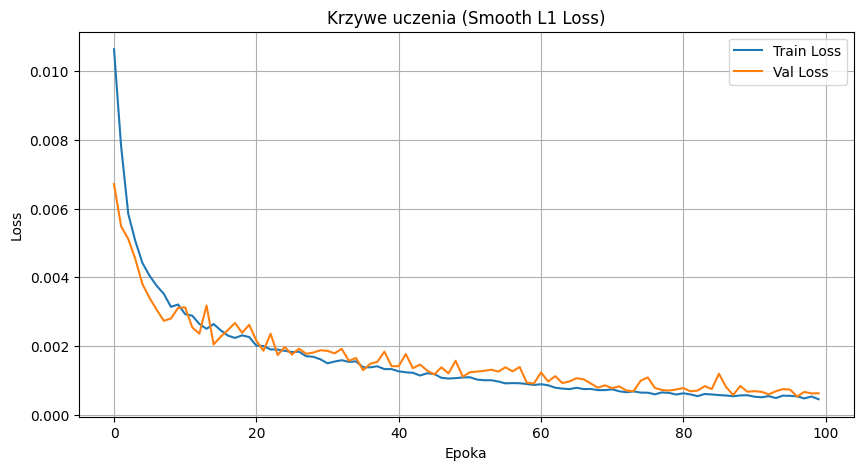

In [ ]:
plot_history(history)

In [ ]:
SEKCJA STOP

In [ ]:
def train_network(model, dataloader, n_epochs):
  loss_mse = nn.MSELoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
  model.train()
  for epoch in range(n_epochs):
    loss_sum = 0.0
    for images, labels in dataloader:
      images = images.to(device)
      labels = labels.to(device)

      predictions = model(images)

      loss = loss_mse(predictions, labels)

      optimizer.zero_grad()

      loss.backward()

      optimizer.step()

      loss_sum += loss.item()

    loss_avg = loss_sum / len(dataloader)
    print(f"Epoch {epoch+1}/{n_epochs}: Average Loss = {loss_avg}")

  return model

In [ ]:
train_network(model=model, dataloader=dataloader, n_epochs=30)

Epoch 1/30: Average Loss = 0.13499553270992778
Epoch 2/30: Average Loss = 0.055634171066303105
Epoch 3/30: Average Loss = 0.04256514749593205
Epoch 4/30: Average Loss = 0.03685311393605338
Epoch 5/30: Average Loss = 0.033743017308768775
Epoch 6/30: Average Loss = 0.027330434925499417
Epoch 7/30: Average Loss = 0.027369429106040608
Epoch 8/30: Average Loss = 0.02191926221111937
Epoch 9/30: Average Loss = 0.019653374181380346
Epoch 10/30: Average Loss = 0.01697106264709007
Epoch 11/30: Average Loss = 0.015404797868714445
Epoch 12/30: Average Loss = 0.013767485329437824
Epoch 13/30: Average Loss = 0.012199055957829668
Epoch 14/30: Average Loss = 0.010437081006192972
Epoch 15/30: Average Loss = 0.009027232231187916
Epoch 16/30: Average Loss = 0.008432938576868129
Epoch 17/30: Average Loss = 0.007457412919768739
Epoch 18/30: Average Loss = 0.006707087388291719
Epoch 19/30: Average Loss = 0.006221685920738512
Epoch 20/30: Average Loss = 0.005712959863659408
Epoch 21/30: Average Loss = 0.0053

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
transforms_B = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5], std=[0.5])
        ])

In [ ]:
device_B = torch.device("cpu")
model.to(device_B)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
def find_circle_B(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    #cy, cx, r = find_circle_baseline(pil_img)
    device_B = torch.device("cpu")
    #model.to(device_B)
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    model.eval()
    image_tensor = transforms_B(pil_img).unsqueeze(0).to(device_B)
    with torch.no_grad():
      output = model(image_tensor)
      prediction = output.squeeze(0).cpu().numpy()

    cy = np.clip(prediction[0], 0, 1) * h
    cx = np.clip(prediction[1], 0, 1) * w
    r = np.clip(prediction[2], 0, max(w,h)) * max(h, w)

    cx = int(np.round(cx))
    cy = int(np.round(cy))
    r = int(np.round(r))
    return cy, cx, r

In [ ]:
# new
results_B = run_all(val_set, algo=find_circle_B)

results_df = pd.DataFrame(results_B)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 60.0%, Accuracy: 88.20%


In [ ]:
# ordering = train_set
ordering = df.index
# ordering = (df["r"] / df["w"]).sort_values(ascending=True).index
# ordering = results_df.sort_values("iou", ascending=True).index
show_results(ordering, algo=find_circle_B)

interactive(children=(IntSlider(value=0, description='i', max=99), Output()), _dom_classes=('widget-interact',…

In [ ]:
from numba import njit

In [ ]:
def find_circle_fundus(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    # 1. Konwersja na skalę szarości
    image_np = np.array(pil_img.convert("L"))
    h, w = image_np.shape

    # ==========================================
    # WIEDZA Z DOMENY (Zasady z Twojego polecenia)
    # ==========================================
    cy_min, cy_max = int(0.3 * h), int(0.7 * h)
    cx_min, cx_max = int(0.3 * w), int(0.7 * w)
    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # 2. Binarizacja (Odcięcie czarnej ramki)
    # Zdjęcia dna oka mają na brzegach pure-black. Odcinamy wszystko poniżej 15.
    _, thresh = cv2.threshold(image_np, 15, 255, cv2.THRESH_BINARY)

    # Oczyszczanie maski z artefaktów (dla wyższych poziomów trudności 10-90)
    # Zamyka dziury w siatkówce i usuwa szum z czarnego tła
    kernel = np.ones((7, 7), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # 3. Znalezienie siatkówki
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # Bierzemy największą plamę (ignorujemy małe białe plamki od szumu)
        largest_contour = max(contours, key=cv2.contourArea)

        # cv2.minEnclosingCircle rysuje najmniejsze idealne koło obejmujące naszą plamę
        (cx_float, cy_float), r_float = cv2.minEnclosingCircle(largest_contour)
        cx, cy, r = int(cx_float), int(cy_float), int(r_float)
    else:
        # Fallback w przypadku kompletnej ciemności na zdjęciu (trudność 90)
        cx, cy, r = w // 2, h // 2, int((r_min + r_max) / 2)

    # ==========================================
    # TWARDY BEZPIECZNIK (Hard Clipping)
    # ==========================================
    # To gwarantuje, że niezależnie od tego, jak algorytm zgłupieje,
    # wynik NIGDY nie wyjdzie poza zasady z Kaggle!
    cy = int(np.clip(cy, cy_min, cy_max))
    cx = int(np.clip(cx, cx_min, cx_max))
    r = int(np.clip(r, r_min, r_max))

    return cy, cx, r

In [ ]:
# new
results_fundus = run_all(val_set, algo=find_circle_fundus)

results_df = pd.DataFrame(results_fundus)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 38.0%, Accuracy: 88.49%


In [ ]:

import scipy.linalg

def fit_circle_least_squares(x, y):
    """
    Algebraiczne dopasowanie okręgu do chmury punktów (Metoda najmniejszych kwadratów).
    Niewrażliwe na pojedyncze odchylenia i wypustki.
    """
    # Budujemy układ równań: 2x*xc + 2y*yc + C = x^2 + y^2
    A = np.c_[2 * x, 2 * y, np.ones(len(x))]
    b = x**2 + y**2

    # Rozwiązujemy układ równań (Zwraca [xc, yc, C])
    w, _, _, _ = scipy.linalg.lstsq(A, b)

    cx, cy, C = w[0], w[1], w[2]
    # Wyliczamy promień z parametru C
    r = np.sqrt(C + cx**2 + cy**2)

    return int(np.round(cx)), int(np.round(cy)), int(np.round(r))

def find_circle_fundus_smart(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    image_np = np.array(pil_img.convert("L"))
    h, w = image_np.shape

    # Zasady domeny
    cy_min, cy_max = int(0.3 * h), int(0.7 * h)
    cx_min, cx_max = int(0.3 * w), int(0.7 * w)
    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # 1. Binarizacja (odcinamy tło)
    _, thresh = cv2.threshold(image_np, 15, 255, cv2.THRESH_BINARY)

    # Czyszczenie morfologiczne maski
    kernel = np.ones((7, 7), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    # 2. Znalezienie krawędzi
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)

        # Wyciągamy WSZYSTKIE współrzędne X i Y z krawędzi siatkówki
        points = largest_contour.reshape(-1, 2)
        x_coords = points[:, 0]
        y_coords = points[:, 1]

        # 3. Odpalamy naszą matematykę - Least Squares Fit!
        cx, cy, r = fit_circle_least_squares(x_coords, y_coords)
    else:
        cx, cy, r = w // 2, h // 2, int((r_min + r_max) / 2)

    # Zabezpieczenie fizyczne z polecenia
    cy = int(np.clip(cy, cy_min, cy_max))
    cx = int(np.clip(cx, cx_min, cx_max))
    r = int(np.clip(r, r_min, r_max))

    return cy, cx, r

In [ ]:
# new
results_fundus_2 = run_all(val_set, algo=find_circle_fundus_smart)

results_df = pd.DataFrame(results_fundus_2)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 37.0%, Accuracy: 87.26%


In [ ]:


def find_circle_B(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    # 1. Konwersja do skali szarości i numpy
    image_np = np.array(pil_img.convert("L"))
    h, w = image_np.shape

    # ==========================================
    # WIEDZA Z DOMENY (Twarde zasady zadania)
    # ==========================================
    cy_min, cy_max = int(0.3 * h), int(0.7 * h)
    cx_min, cx_max = int(0.3 * w), int(0.7 * w)
    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # ==========================================
    # PREPROCESSING (Pancerz na szumy)
    # ==========================================
    # Dynamiczny rozmiar filtra Medianowego (usuwa potężny szum, sól/pieprz, czarne dziury)
    # Musi być nieparzysty. Dla obrazka 1000px to będzie filtr 15x15
    median_ksize = int(min(h, w) * 0.015) // 2 * 2 + 1
    median_ksize = max(3, median_ksize) # Zabezpieczenie przed za małym filtrem
    blurred = cv2.medianBlur(image_np, median_ksize)

    # CLAHE, żeby wyciągnąć krawędź oka nawet z niedoświetlonego tła
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(blurred)

    # ==========================================
    # DETEKCJA: HOUGH GRADIENT ALT
    # ==========================================
    # HOUGH_GRADIENT_ALT to nowoczesna, wysoce precyzyjna wersja transformaty.
    circles = cv2.HoughCircles(
        enhanced,
        cv2.HOUGH_GRADIENT_ALT,
        dp=1.5,                    # Rozdzielczość akumulatora
        minDist=min(h, w),         # Chcemy znaleźć tylko JEDEN najlepszy okrąg
        param1=300,                # Twardy próg detekcji krawędzi (Canny) - ignoruje słabe szumy
        param2=0.85,               # "Perfekcyjność" okręgu (0.0 - 1.0). 0.85 to wysoki rygor.
        minRadius=r_min,
        maxRadius=r_max
    )

    # ==========================================
    # ANALIZA WYNIKÓW I FALLBACK
    # ==========================================
    if circles is not None:
        # circles ma kształt (1, N, 3), bierzemy pierwszy (najlepszy) okrąg
        cx, cy, r = np.round(circles[0][0]).astype(int)
    else:
        # Jeśli szum jest tak potężny (trudność 90), że Hough nic nie znalazł (awaria),
        # minimalizujemy straty "strzelając" w środek z uśrednionym promieniem.
        # Accuracy/IoU na pewno spadnie, ale przynajmniej skrypt się nie wywali.
        cx, cy = w // 2, h // 2
        r = int((r_min + r_max) / 2)

    # Ostatnia linia obrony: Hard Clipping do limitów z zadania
    cy = int(np.clip(cy, cy_min, cy_max))
    cx = int(np.clip(cx, cx_min, cx_max))
    r  = int(np.clip(r, r_min, r_max))

    return cy, cx, r

In [ ]:
# new
find_circle_B = run_all(val_set, algo=find_circle_B)

results_df = pd.DataFrame(find_circle_B)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 27.0%, Accuracy: 87.46%


In [ ]:
def find_circle_B(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    # 1. ZMIANA PRZESTRZENI: Zamiast skali szarości, izolujemy KANAŁ ZIELONY (Green)
    # Konwertujemy do RGB i bierzemy kanał o indeksie 1 (R=0, G=1, B=2)
    img_rgb = np.array(pil_img.convert("RGB"))
    img_green = img_rgb[:, :, 1]

    h, w = img_green.shape

    # Zasady fizyczne z polecenia
    cy_min, cy_max = int(0.3 * h), int(0.7 * h)
    cx_min, cx_max = int(0.3 * w), int(0.7 * w)
    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # 2. PREPROCESSING Z TWOIMI PARAMETRAMI
    # Twardy Median Blur 21 (Niszczy szum Kaggle, zachowuje ostre brzegi)
    blurred = cv2.medianBlur(img_green, 21)

    # CLAHE: Clip 3.0, Tile 4x4
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4))
    enhanced = clahe.apply(blurred)

    # 3. DETEKCJA HOUGH ALT
    circles = cv2.HoughCircles(
        enhanced,
        cv2.HOUGH_GRADIENT_ALT,
        dp=1.5,
        minDist=min(h, w),
        param1=250,      # Lekko obniżony próg krawędzi (łapie więcej detali z ciemności)
        param2=0.80,     # Większa tolerancja na nieidealne, uszkodzone szumem okręgi
        minRadius=r_min,
        maxRadius=r_max
    )

    # 4. FALLBACK I ZABEZPIECZENIA
    if circles is not None:
        cx, cy, r = np.round(circles[0][0]).astype(int)
    else:
        # Strzał awaryjny
        cx, cy, r = w // 2, h // 2, int((r_min + r_max) / 2)

    # Hard Clipping (Ostatnia linia obrony)
    cy = int(np.clip(cy, cy_min, cy_max))
    cx = int(np.clip(cx, cx_min, cx_max))
    r  = int(np.clip(r, r_min, r_max))

    return cy, cx, r

In [ ]:
# new
find_circle_B = run_all(val_set, algo=find_circle_B)

results_df = pd.DataFrame(find_circle_B)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 25.0%, Accuracy: 87.25%


In [ ]:
def create_algo_B(blur_size=21, param1=250, param2=0.8):
    """
    Fabryka algorytmów. Zwraca funkcję find_circle_B z wstrzykniętymi parametrami.
    """
    def find_circle_B(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
        # 1. Zwykła skala szarości (zgodnie z Twoją prośbą)
        image_np = np.array(pil_img.convert("L"))
        h, w = image_np.shape

        cy_min, cy_max = int(0.3 * h), int(0.7 * h)
        cx_min, cx_max = int(0.3 * w), int(0.7 * w)
        r_min = int(0.25 * max(h, w))
        r_max = int(0.75 * min(h, w))

        # 2. Zmiana na GaussianBlur
        blurred = cv2.GaussianBlur(image_np, (blur_size, blur_size), 0)

        # Delikatniejsze CLAHE
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced = clahe.apply(blurred)

        # 3. Hough z dynamicznymi parametrami
        circles = cv2.HoughCircles(
            enhanced,
            cv2.HOUGH_GRADIENT_ALT,
            dp=1.5,
            minDist=min(h, w),
            param1=param1,
            param2=param2,
            minRadius=r_min,
            maxRadius=r_max
        )

        if circles is not None:
            cx, cy, r = np.round(circles[0][0]).astype(int)
        else:
            cx, cy, r = w // 2, h // 2, int((r_min + r_max) / 2)

        # Zabezpieczenie fizyczne
        cy = int(np.clip(cy, cy_min, cy_max))
        cx = int(np.clip(cx, cx_min, cx_max))
        r  = int(np.clip(r, r_min, r_max))

        return cy, cx, r

    return find_circle_B

In [ ]:
class AlgoB_Runner:
    def __init__(self, blur_size, param1, param2):
        self.blur_size = blur_size
        self.param1 = param1
        self.param2 = param2

    def __call__(self, pil_img: PIL.Image.Image) -> tuple[int, int, int]:
        # 1. Skala szarości
        image_np = np.array(pil_img.convert("L"))
        h, w = image_np.shape

        # 2. Fizyka
        cy_min, cy_max = int(0.3 * h), int(0.7 * h)
        cx_min, cx_max = int(0.3 * w), int(0.7 * w)
        r_min = int(0.25 * max(h, w))
        r_max = int(0.75 * min(h, w))

        # 3. Preprocessing (Gauss + CLAHE)
        blurred = cv2.GaussianBlur(image_np, (self.blur_size, self.blur_size), 0)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced = clahe.apply(blurred)

        # 4. Detekcja
        circles = cv2.HoughCircles(
            enhanced,
            cv2.HOUGH_GRADIENT_ALT,
            dp=1.5,
            minDist=min(h, w),
            param1=self.param1,
            param2=self.param2,
            minRadius=r_min,
            maxRadius=r_max
        )

        if circles is not None:
            cx, cy, r = np.round(circles[0][0]).astype(int)
        else:
            cx, cy, r = w // 2, h // 2, int((r_min + r_max) / 2)

        # 5. Bezpiecznik z ograniczeniami Kaggle
        cy = int(np.clip(cy, cy_min, cy_max))
        cx = int(np.clip(cx, cx_min, cx_max))
        r  = int(np.clip(r, r_min, r_max))

        return cy, cx, r

In [ ]:
# ==========================================
# 2. PĘTLA GRID SEARCH
# ==========================================
grid_blur_sizes = [11, 21, 31, 41]
grid_param1 = [100, 200, 300]
grid_param2 = [0.6, 0.7, 0.8, 0.85]

best_success_rate = -1.0
best_params = None
results_log = []

print("Rozpoczynam Grid Search (Tym razem bez crasha!)...")

for b, p1, p2 in itertools.product(grid_blur_sizes, grid_param1, grid_param2):

    # Tworzymy nasz "callable object" (dla run_all wygląda jak zwykła funkcja!)
    current_algo = AlgoB_Runner(blur_size=b, param1=p1, param2=p2)

    # Odpalamy ewaluację
    results = run_all(val_set, algo=current_algo)

    df = pd.DataFrame(results)
    success_rate = (df["iou"] >= 0.85).mean()
    accuracy = df["iou"].clip(0.85, 0.98).mean()

    print(f"[Blur: {b:2d} | p1: {p1:3d} | p2: {p2:.2f}] -> Success: {success_rate:.1%}, Acc: {accuracy:.2%}")

    results_log.append({
        'blur': b, 'param1': p1, 'param2': p2,
        'success': success_rate, 'acc': accuracy
    })

    if success_rate > best_success_rate:
        best_success_rate = success_rate
        best_params = (b, p1, p2)

print("="*50)
print(f"🔥 NAJLEPSZE PARAMETRY: Blur={best_params[0]}, param1={best_params[1]}, param2={best_params[2]}")
print(f"🔥 NAJLEPSZY SUCCESS RATE: {best_success_rate:.1%}")
print("="*50)

Rozpoczynam Grid Search (Tym razem bez crasha!)...


  0%|          | 0/100 [00:00<?, ?it/s]

[Blur: 11 | p1: 100 | p2: 0.60] -> Success: 24.0%, Acc: 87.09%


  0%|          | 0/100 [00:00<?, ?it/s]

[Blur: 11 | p1: 100 | p2: 0.70] -> Success: 24.0%, Acc: 87.09%


  0%|          | 0/100 [00:00<?, ?it/s]

... (35 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

[Blur: 21 | p1: 300 | p2: 0.60] -> Success: 21.0%, Acc: 86.74%


  0%|          | 0/100 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:


@numba.njit
def fit_circle_3pts(p1, p2, p3):
    """
    Fits a circle to 3 points (x, y).
    Returns (cy, cx, r). If points are collinear, returns (0, 0, -1).
    """
    x1, y1 = p1
    x2, y2 = p2
    x3, y3 = p3

    det = x1*(y2 - y3) - y1*(x2 - x3) + (x2*y3 - x3*y2)

    if abs(det) < 1e-6:
        return 0.0, 0.0, -1.0

    v1 = -(x1*x1 + y1*y1)
    v2 = -(x2*x2 + y2*y2)
    v3 = -(x3*x3 + y3*y3)

    detA = v1*(y2 - y3) - y1*(v2 - v3) + (v2*y3 - v3*y2)
    detB = x1*(v2 - v3) - v1*(x2 - x3) + (x2*v3 - x3*v2)
    detC = x1*(y2*v3 - y3*v2) - y1*(x2*v3 - x3*v2) + v1*(x2*y3 - x3*y2)

    A = detA / det
    B = detB / det
    C = detC / det

    cx = -A / 2.0
    cy = -B / 2.0
    r = np.sqrt(max(0.0, cx*cx + cy*cy - C))

    return cy, cx, r

@numba.njit
def evaluate_circle(pts, cy, cx, r, margin):
    """
    Counts how many points fall within `margin` distance from the circle border.
    pts is an array of (y, x).
    """
    inliers = 0
    for i in range(len(pts)):
        y = pts[i, 0]
        x = pts[i, 1]
        dist = np.sqrt((x - cx)**2 + (y - cy)**2)
        if abs(dist - r) < margin:
            inliers += 1
    return inliers

@numba.njit
def ransac_loop(pts_array, max_iters, margin):
    n_pts = len(pts_array)
    best_inliers = -1
    best_circle = (0.0, 0.0, -1.0)

    for i in range(max_iters):
        # sample 3 distinct points
        i1 = np.random.randint(0, n_pts)
        i2 = np.random.randint(0, n_pts)
        while i2 == i1:
            i2 = np.random.randint(0, n_pts)
        i3 = np.random.randint(0, n_pts)
        while i3 == i1 or i3 == i2:
            i3 = np.random.randint(0, n_pts)

        p1 = pts_array[i1]
        p2 = pts_array[i2]
        p3 = pts_array[i3]

        # p is (y, x), we need (x, y) for fit_circle_3pts
        cy, cx, r = fit_circle_3pts((p1[1], p1[0]), (p2[1], p2[0]), (p3[1], p3[0]))

        if r <= 0:
            continue

        inliers = evaluate_circle(pts_array, cy, cx, r, margin)

        if inliers > best_inliers:
            best_inliers = inliers
            best_circle = (cy, cx, r)

    return best_circle, best_inliers

def ransac_circle_fit(pts_yx, max_iters=2000, margin=5.0):
    if len(pts_yx) < 3:
        return None

    pts_array = np.array(pts_yx, dtype=np.float64)
    best_circle, best_inliers = ransac_loop(pts_array, max_iters, margin)

    if best_inliers >= 0:
        return best_circle, best_inliers
    return None

def preprocess_for_contour(pil_img: PIL.Image.Image):
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    # Convert to grayscale
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # Apply CLAHE
    clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(8, 8))
    image_gray = clahe.apply(image_gray)

    # Heavy median blur to eliminate internal eye structure while preserving edges
    blur_k = min(31, min(h, w) // 2 | 1)
    image_smoothed = cv2.medianBlur(image_gray, blur_k)

    # Binary threshold (Otsu's method)
    _, binary = cv2.threshold(image_smoothed, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Morphological closing and opening to clean up
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    return binary

def find_circle_B(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    binary = preprocess_for_contour(pil_img)

    # Find contours
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    valid_circle = False
    best_cy, best_cx, best_r = h // 2, w // 2, min(h, w) // 2

    if contours:
        # Sort contours by area
        contours = sorted(contours, key=cv2.contourArea, reverse=True)
        largest_contour = contours[0]

        pts = largest_contour.reshape(-1, 2)
        # convert to (y, x) for RANSAC
        pts_yx = np.column_stack((pts[:, 1], pts[:, 0]))

        if len(pts_yx) >= 3:
            res = ransac_circle_fit(pts_yx, max_iters=3000, margin=5.0)
            if res is not None:
                circle, inliers = res
                cy, cx, r = circle

                # Basic validation of the found circle
                if r > 0.25 * max(h, w) and r < 0.75 * max(h, w):
                    c_dist = np.hypot(cy - h/2, cx - w/2)
                    if c_dist < 0.3 * max(h, w):
                        valid_circle = True
                        best_cy, best_cx, best_r = cy, cx, r

    if not valid_circle:
        # Fallback to cv2.minEnclosingCircle on the largest contour if RANSAC fails
        if contours:
            (cx, cy), r = cv2.minEnclosingCircle(contours[0])
            if r > 0.25 * max(h, w) and r < 0.75 * max(h, w):
                c_dist = np.hypot(cy - h/2, cx - w/2)
                if c_dist < 0.3 * max(h, w):
                    valid_circle = True
                    best_cy, best_cx, best_r = cy, cx, r

    if not valid_circle:
        # Final Fallback to HoughCircles
        image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)
        clahe = cv2.createCLAHE(clipLimit=3, tileGridSize=(4,4))
        image_gray = clahe.apply(image_gray)
        image_smoothed = cv2.GaussianBlur(image_gray, (21, 21), 0)

        r_min = int(0.25 * max(h, w))
        r_max = int(0.75 * min(h, w))

        circles = cv2.HoughCircles(
            image_smoothed,
            cv2.HOUGH_GRADIENT,
            minDist=min(h, w),
            dp=1,
            param1=100,
            param2=40,
            minRadius=r_min,
            maxRadius=r_max
        )
        if circles is not None:
            best_cx, best_cy, best_r = circles[0][0]

    return int(np.round(best_cy)), int(np.round(best_cx)), int(np.round(best_r))


In [ ]:
# new
find_circle_B = run_all(val_set, algo=find_circle_B)

results_df = pd.DataFrame(find_circle_B)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 70.0%, Accuracy: 93.72%


In [ ]:
def find_circle_C(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    """
    Advanced circle detection using cv2.HOUGH_GRADIENT_ALT and optimized preprocessing.
    """
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    # Convert to grayscale
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # 1. Contrast enhancement via CLAHE
    # tileGridSize=(8,8) is standard, clipLimit=2 or 3 works well for fundus images
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    image_gray = clahe.apply(image_gray)

    # 2. Advanced smoothing
    # Median blur is great at removing noise/vessels without blurring edges too much
    image_smoothed = cv2.medianBlur(image_gray, 15)

    # 3. Morphological operations
    # Opening removes small bright artifacts, Closing removes small dark artifacts
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    image_smoothed = cv2.morphologyEx(image_smoothed, cv2.MORPH_OPEN, kernel)

    # Further slight gaussian blur for smooth gradients
    image_smoothed = cv2.GaussianBlur(image_smoothed, (9, 9), 0)

    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # Check if HOUGH_GRADIENT_ALT is available
    if hasattr(cv2, 'HOUGH_GRADIENT_ALT'):
        method = cv2.HOUGH_GRADIENT_ALT
        param1 = 300  # Canny threshold
        param2 = 0.85 # Perfectness measure for ALT
    else:
        method = cv2.HOUGH_GRADIENT
        param1 = 100
        param2 = 30

    circles = cv2.HoughCircles(
        image_smoothed,
        method,
        minDist=min(h, w) * 0.8, # We only expect one major circle
        dp=1.5 if method == cv2.HOUGH_GRADIENT_ALT else 1.0,
        param1=param1,
        param2=param2,
        minRadius=r_min,
        maxRadius=r_max
    )

    valid_circle = False
    best_cy, best_cx, best_r = h // 2, w // 2, min(h, w) // 2

    if circles is not None:
        # Sort by confidence/votes if using HOUGH_GRADIENT
        # HOUGH_GRADIENT_ALT sorts by radius? The documentation says it sorts by weight, but we take the first.
        circle = circles[0][0]
        cx, cy, r = circle

        # Validation checks
        c_dist = np.hypot(cy - h/2, cx - w/2)
        if c_dist < 0.4 * max(h, w):
            valid_circle = True
            best_cy, best_cx, best_r = cy, cx, r

    if not valid_circle:
        # Fallback to very permissive HOUGH_GRADIENT if ALT failed or was too strict
        circles_fallback = cv2.HoughCircles(
            image_smoothed,
            cv2.HOUGH_GRADIENT,
            minDist=min(h, w) * 0.8,
            dp=1.0,
            param1=100,
            param2=20,
            minRadius=r_min,
            maxRadius=r_max
        )
        if circles_fallback is not None:
            circle = circles_fallback[0][0]
            cx, cy, r = circle
            best_cy, best_cx, best_r = cy, cx, r

    return int(np.round(best_cy)), int(np.round(best_cx)), int(np.round(best_r))


In [ ]:
# new
find_circle_C = run_all(val_set, algo=find_circle_C)

results_df = pd.DataFrame(find_circle_C)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 78.0%, Accuracy: 94.42%


In [ ]:
def find_circle_D(pil_img: PIL.Image.Image) -> tuple[int, int, int]:
    """
    Highly optimized circle detection utilizing binary mask preprocessing
    and cv2.HoughCircles to maximize accuracy by completely removing internal edges.
    """
    image_np = np.array(pil_img)
    h, w = image_np.shape[:2]

    # 1. Convert to grayscale
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # 2. Strong CLAHE to pop the edge out from dark background regions
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    image_gray = clahe.apply(image_gray)

    # 3. Extreme Median Blur to wipe out internal eye structure and noise,
    # but preserve the strong circular outer edge.
    blur_k = min(31, min(h, w) // 2 | 1)
    image_smoothed = cv2.medianBlur(image_gray, blur_k)

    # 4. Otsu's thresholding to generate a strict binary mask
    _, binary = cv2.threshold(image_smoothed, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 5. Massive morphological operations to heal any remaining gaps or islands
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    # 6. Gentle Gaussian Blur on the binary mask so the internal Canny detector
    # of HoughCircles sees a smooth gradient rather than a jagged 1-pixel step.
    binary_blurred = cv2.GaussianBlur(binary, (15, 15), 0)

    # Expected radius constraints
    r_min = int(0.25 * max(h, w))
    r_max = int(0.75 * min(h, w))

    # Decide which Hough method to use based on OpenCV version
    if hasattr(cv2, 'HOUGH_GRADIENT_ALT'):
        method = cv2.HOUGH_GRADIENT_ALT
        # For ALT on a binary mask, edges are extremely strong.
        # param1=300 is totally fine.
        # param2=0.85 requires a very circular shape.
        param1 = 300
        param2 = 0.85
        dp = 1.5
    else:
        method = cv2.HOUGH_GRADIENT
        # For standard Hough on binary image, gradients are 0 or max.
        param1 = 50
        param2 = 30 # Accumulator threshold. Since it's clean, standard 30-40 works well.
        dp = 1.0

    # 7. Run HoughCircles on the prepared binary mask
    circles = cv2.HoughCircles(
        binary_blurred,
        method,
        minDist=min(h, w) * 0.8,
        dp=dp,
        param1=param1,
        param2=param2,
        minRadius=r_min,
        maxRadius=r_max
    )

    valid_circle = False
    best_cy, best_cx, best_r = h // 2, w // 2, min(h, w) // 2

    if circles is not None:
        circle = circles[0][0]
        cx, cy, r = circle

        # Validation checks
        c_dist = np.hypot(cy - h/2, cx - w/2)
        if c_dist < 0.4 * max(h, w):
            valid_circle = True
            best_cy, best_cx, best_r = cy, cx, r

    if not valid_circle:
        # Fallback 1: More permissive HOUGH_GRADIENT on the binary mask
        circles_fallback = cv2.HoughCircles(
            binary_blurred,
            cv2.HOUGH_GRADIENT,
            minDist=min(h, w) * 0.8,
            dp=1.0,
            param1=50,
            param2=15,
            minRadius=r_min,
            maxRadius=r_max
        )
        if circles_fallback is not None:
            circle = circles_fallback[0][0]
            cx, cy, r = circle
            best_cy, best_cx, best_r = cy, cx, r
        else:
            # Fallback 2: Enclosing circle on the contour of the mask
            contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if contours:
                contours = sorted(contours, key=cv2.contourArea, reverse=True)
                (cx, cy), r = cv2.minEnclosingCircle(contours[0])
                best_cy, best_cx, best_r = cy, cx, r

    return int(np.round(best_cy)), int(np.round(best_cx)), int(np.round(best_r))

In [ ]:
# new
find_circle_D = run_all(val_set, algo=find_circle_D)

results_df = pd.DataFrame(find_circle_D)
results_df["difficulty"] = results_df["path"].map(lambda p: p.split("/")[1])
results_df["index"] = results_df["path"].apply(lambda p: IMG_DIR / p)
results_df = results_df.drop_duplicates(subset="index", keep="last").set_index("index")
results_df

success_rate = (results_df["iou"] >= 0.85).mean()
accuracy = results_df["iou"].clip(0.85, 0.98).mean()
print(f"Success Rate: {success_rate:.1%}, Accuracy: {accuracy:.2%}")

  0%|          | 0/100 [00:00<?, ?it/s]

Success Rate: 78.0%, Accuracy: 94.53%
